In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mplsoccer import Pitch, Sbopen, VerticalPitch
import mplsoccer
import sympy as sp
from scipy.interpolate import griddata
import numpy as np
import matplotlib.animation as animation
from IPython.display import HTML
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
import io
from PIL import Image
import requests
from bs4 import BeautifulSoup
from statsbombpy import sb
import json
import csv
import networkx as nx

# SELECTING THE REQUIRED DATA SET AND IMPORTING IT TO THE DATAFRAME

In [2]:
#IMPORTING THE FULL THING AND SEEING WHICH DATASETS ARE AVAILABLE
comps=sb.competitions()
comps['competition_name'].unique()

array(['1. Bundesliga', 'African Cup of Nations', 'Champions League',
       'Copa America', 'Copa del Rey', "FA Women's Super League",
       'FIFA U20 World Cup', 'FIFA World Cup', 'Indian Super league',
       'La Liga', 'Liga Profesional', 'Ligue 1', 'Major League Soccer',
       'North American League', 'NWSL', 'Premier League', 'Serie A',
       'UEFA Euro', 'UEFA Europa League', "UEFA Women's Euro",
       "Women's World Cup"], dtype=object)

In [3]:
#SELECTING THE COMPETETION ACCORDING TO THE PROBLEM
comps_pro=comps[comps['competition_name']=='Serie A']
comps_pro

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
66,12,27,Italy,Serie A,male,False,False,2015/2016,2025-07-21T05:01:00.434081,None,None,2025-07-21T05:01:00.434081
67,12,86,Italy,Serie A,male,False,False,1986/1987,2023-06-18T01:55:53.343752,None,None,2023-06-18T01:55:53.343752


In [4]:
#INSPECTING MATCH ID AND SEASON ID TO SELECT THE MATCH/MATCHES YOU NEED
matches=sb.matches(competition_id=43,season_id=106)
matches

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,...,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version
0,3857256,2022-12-02,21:00:00.000,International - FIFA World Cup,2022,Serbia,Switzerland,2,3,available,...,2023-04-26T23:49:58.956186,3,Group Stage,Stadium 974,Fernando Andrés Rapallini,Dragan Stojković,Murat Yakin,1.1.0,2,2
1,3869151,2022-12-03,21:00:00.000,International - FIFA World Cup,2022,Argentina,Australia,2,1,available,...,2023-07-30T07:48:51.865595,4,Round of 16,Ahmad bin Ali Stadium,Szymon Marciniak,Lionel Sebastián Scaloni,Graham James Arnold,1.1.0,2,2
2,3857257,2022-11-30,17:00:00.000,International - FIFA World Cup,2022,Australia,Denmark,1,0,available,...,2023-06-20T11:04:37.638969,3,Group Stage,Al Janoub Stadium,Mustapha Ghorbal,Graham James Arnold,Kasper Hjulmand,1.1.0,2,2
3,3857258,2022-11-24,21:00:00.000,International - FIFA World Cup,2022,Brazil,Serbia,2,0,available,...,2023-07-11T14:56:31.096588,1,Group Stage,Lusail Stadium,Alireza Faghani,Telê Santana da Silva,Dragan Stojković,1.1.0,2,2
4,3857288,2022-11-26,12:00:00.000,International - FIFA World Cup,2022,Tunisia,Australia,0,1,available,...,2023-04-27T00:30:07.835815,2,Group Stage,Al Janoub Stadium,Daniel Siebert,Jalel Kadri,Graham James Arnold,1.1.0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,3857265,2022-11-22,18:00:00.000,International - FIFA World Cup,2022,Mexico,Poland,0,0,available,...,2023-04-27T00:49:30.005344,1,Group Stage,Stadium 974,Chris Beath,Gerardo Daniel Martino,Czesław Michniewicz,1.1.0,2,2
60,3857262,2022-12-02,17:00:00.000,International - FIFA World Cup,2022,South Korea,Portugal,2,1,available,...,2023-04-26T23:48:08.999798,3,Group Stage,Education City Stadium,Facundo Tello Figueroa,Paulo Jorge Gomes Bento,Fernando Manuel Fernandes da Costa Santos,1.1.0,2,2
61,3857261,2022-11-29,21:00:00.000,International - FIFA World Cup,2022,Wales,England,0,3,available,...,2023-04-27T00:02:44.241621,3,Group Stage,Ahmad bin Ali Stadium,Slavko Vinčić,Robert Page,Gareth Southgate,1.1.0,2,2
62,3857255,2022-12-01,21:00:00.000,International - FIFA World Cup,2022,Japan,Spain,2,1,available,...,2023-04-26T23:51:48.352990,3,Group Stage,Sheikh Khalifa International Stadium,Victor Miguel de Freitas Gomes,Hajime Moriyasu,Luis Enrique Martínez García,1.1.0,2,2


In [5]:
#SELECTING THE TEAMS ENTIRE MATCHES DURING THE TOURNAMENT
matches_AGH=matches[(matches['home_team']=='Argentina')]
matches_AGA=matches[(matches['away_team']=='Argentina')]
AG_all=[matches_AGH,matches_AGA]
matches_AG=pd.concat(AG_all)
matches_AG

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,match_status,...,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version
1,3869151,2022-12-03,21:00:00.000,International - FIFA World Cup,2022,Argentina,Australia,2,1,available,...,2023-07-30T07:48:51.865595,4,Round of 16,Ahmad bin Ali Stadium,Szymon Marciniak,Lionel Sebastián Scaloni,Graham James Arnold,1.1.0,2,2
9,3869685,2022-12-18,17:00:00.000,International - FIFA World Cup,2022,Argentina,France,3,3,available,...,2023-08-17T15:55:15.164685,7,Final,Lusail Stadium,Szymon Marciniak,Lionel Sebastián Scaloni,Didier Deschamps,1.1.0,2,2
13,3857289,2022-11-26,21:00:00.000,International - FIFA World Cup,2022,Argentina,Mexico,2,0,available,...,2023-06-20T11:57:08.547882,2,Group Stage,Lusail Stadium,Daniele Orsato,Lionel Sebastián Scaloni,Gerardo Daniel Martino,1.1.0,2,2
19,3869519,2022-12-13,21:00:00.000,International - FIFA World Cup,2022,Argentina,Croatia,3,0,available,...,2023-04-26T22:32:37.808359,6,Semi-finals,Lusail Stadium,Daniele Orsato,Lionel Sebastián Scaloni,Zlatko Dalić,1.1.0,2,2
37,3857300,2022-11-22,12:00:00.000,International - FIFA World Cup,2022,Argentina,Saudi Arabia,1,2,available,...,2023-06-19T15:59:46.628887,1,Group Stage,Lusail Stadium,Slavko Vinčić,Lionel Sebastián Scaloni,Hervé Renard,1.1.0,2,2
6,3869321,2022-12-09,21:00:00.000,International - FIFA World Cup,2022,Netherlands,Argentina,2,2,available,...,2023-06-21T17:51:12.511460,5,Quarter-finals,Lusail Stadium,Antonio Miguel Mateu Lahoz,Louis van Gaal,Lionel Sebastián Scaloni,1.1.0,2,2
11,3857264,2022-11-30,21:00:00.000,International - FIFA World Cup,2022,Poland,Argentina,0,2,available,...,2023-07-25T09:10:13.832053,3,Group Stage,Stadium 974,Danny Desmond Makkelie,Czesław Michniewicz,Lionel Sebastián Scaloni,1.1.0,2,2


In [6]:
#ARGENTINA MATCH DIRECTORY 2022
#AUSTRALIA-3869151
#FRANCE-3869685
#MEXICO-3857289
#CROATIA-3869519
#SAUDI-3857300
#NETHERLANDS-3869321
#POLAND-3857264

# SCRAPING TRY

# SCRAPING USING SOCCERDATA

# SCRAPING THE WIKIPEDIA FOR THE PREMIER LEAGUE TABLE OF A PARTICULAR YEAR

In [7]:
#EDIT URL TO GET DIFFERENT YEARS
# Wikipedia page URL
url = "https://en.wikipedia.org/wiki/2024%E2%80%9325_Premier_League"

# Set headers to avoid being blocked
headers = {
    "User-Agent": "Mozilla/5.0 (ChatGPT Example)"
}

# 1️⃣ Fetch the page
r = requests.get(url, headers=headers)
soup = BeautifulSoup(r.text, "html.parser")

# 2️⃣ Find the "League table"
# Usually the first table with class "wikitable" in the "League table" section
tables = soup.find_all("table", {"class": "wikitable"})
league_table = tables[0]  # The Premier League table is the first wikitable

# 3️⃣ Extract headers
headers_row = league_table.find("tr")
headers = [th.get_text(strip=True) for th in headers_row.find_all(["th", "td"])]

# 4️⃣ Extract all rows
rows = []
for tr in league_table.find_all("tr")[1:]:  # skip header row
    cells = tr.find_all(["td", "th"])
    row = [cell.get_text(strip=True).replace("\xa0"," ") for cell in cells]
    if row:  # skip empty rows
        rows.append(row)
#EDIT THE FILE NAME TO SAVE IN DIFFERENT FILES
# 5️⃣ Save to CSV
with open("premier_league_2024_25.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(headers)
    writer.writerows(rows)

print("Saved CSV → premier_league_2024_25.csv")


Saved CSV → premier_league_2024_25.csv


In [8]:
#EDIT THE URLS 

# Wikipedia page URL
url = "https://en.wikipedia.org/wiki/2024%E2%80%9325_Premier_League"

headers = {
    "User-Agent": "Mozilla/5.0 (ChatGPT Example)"
}

# 1️⃣ Fetch the page
r = requests.get(url, headers=headers)
soup = BeautifulSoup(r.text, "html.parser")

# 2️⃣ Find all tables in the "Results" section
# The results table has class "wikitable" and is after the heading "Results"
results_heading = soup.find(id="Results")
results_table = results_heading.find_next("table", {"class": "wikitable"})

# 3️⃣ Extract headers (away teams)
header_row = results_table.find("tr")
headers = [th.get_text(strip=True) for th in header_row.find_all("th")]

# 4️⃣ Extract all rows (home teams + scores)
rows = []
for tr in results_table.find_all("tr")[1:]:
    cells = [cell.get_text(strip=True).replace("\xa0"," ") for cell in tr.find_all(["th","td"])]
    if cells:
        rows.append(cells)
#EDIT THE FILE NAMES
# 5️⃣ Save to CSV
with open("premier_league_2024_25_results.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(headers)
    writer.writerows(rows)

print("Saved CSV → premier_league_2022_23_results.csv")


Saved CSV → premier_league_2022_23_results.csv


# ANALYTICS BASICS-1:PLOTTING SHOTS

In [9]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3869685)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
shots = df.loc[df['type_name'] == 'Shot'].set_index('id')

In [10]:
#DISCARDING THE SHOOTOUT
shots = shots[shots['minute']<120]

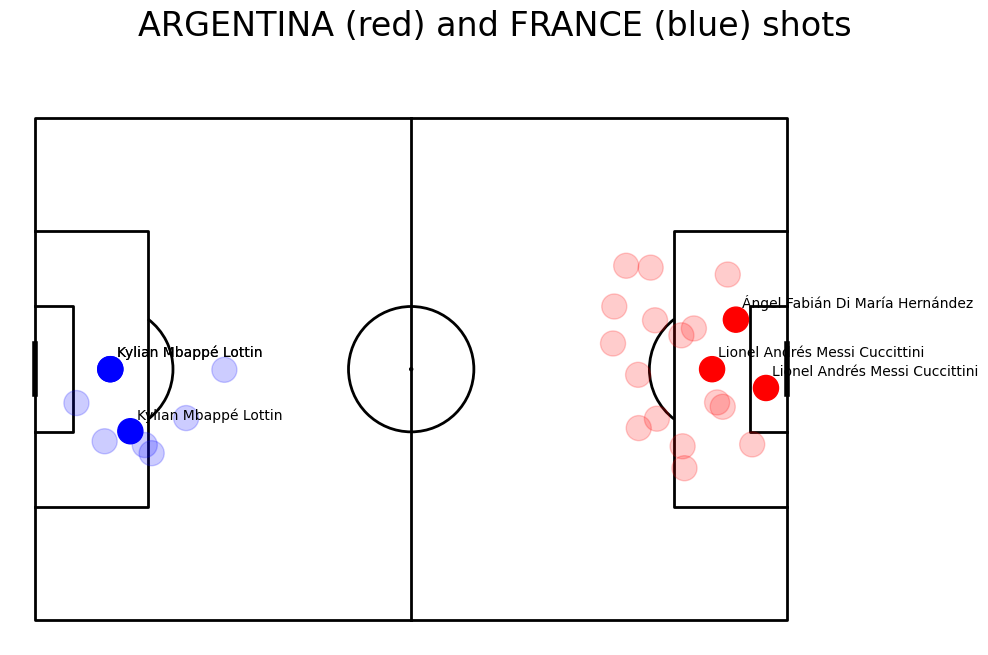

In [11]:
#PLOTTING SHOTS WITH DARKER CIRCLES FOR GOALS
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
#Plot the shots by looping through them.
for i,shot in shots.iterrows():
    #get the information 
    x=shot['x']
    y=shot['y']
    goal=shot['outcome_name']=='Goal'
    team_name=shot['team_name']    
    #set circlesize
    circleSize=2
    #plot England
    if (team_name==team1):
        if goal:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,shot['player_name']) 
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
    #plot Sweden
    else:
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
    ax.add_patch(shotCircle)
#set title
fig.suptitle("ARGENTINA (red) and FRANCE (blue) shots", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

# PASS MAP-(FROM SUMPTER)

In [12]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3869685)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
passes = df.loc[df['type_name'] == 'Pass'].set_index('id')

In [13]:
team1,team2=passes['team_name'].unique()
passes['team_name']

id
f651a6c4-55e3-4e0f-a178-59414ba83d6a       France
a5956ecc-d637-44d2-8705-e2079e12013e       France
5ba6dfab-49f0-4225-bbb6-8b1e27bc729a    Argentina
27829865-a43c-4c50-b545-b09e8a965e16    Argentina
59420b0c-94cc-4fb8-86fb-e1105936f6eb    Argentina
                                          ...    
fc143837-ac4c-4606-84d0-8d4d2c4c1f22    Argentina
cccce9cb-7864-4130-a5d4-55308d3738f4       France
2c132bb4-b135-420e-9cf3-a1ed869bc2a9    Argentina
641f3cd8-283d-4fa9-ac2f-d6c3a22afae3    Argentina
3087edc7-affe-414a-a08d-7887df44156a       France
Name: team_name, Length: 1263, dtype: object

In [14]:
passes['player_name'].unique()

array(['Antoine Griezmann', 'Aurélien Djani Tchouaméni',
       'Nahuel Molina Lucero', 'Rodrigo Javier De Paul',
       'Cristian Gabriel Romero', 'Nicolás Hernán Otamendi',
       'Nicolás Alejandro Tagliafico', 'Damián Emiliano Martínez',
       'Theo Bernard François Hernández', 'Adrien Rabiot',
       'Raphaël Varane', 'Jules Koundé', 'Alexis Mac Allister',
       'Lionel Andrés Messi Cuccittini',
       'Ángel Fabián Di María Hernández', 'Hugo Lloris', 'Olivier Giroud',
       'Enzo Fernandez', 'Kylian Mbappé Lottin', 'Ousmane Dembélé',
       'Julián Álvarez', 'Dayotchanculle Upamecano', 'Randal Kolo Muani',
       'Marcus Thuram', 'Marcos Javier Acuña', 'Eduardo Camavinga',
       'Kingsley Coman', 'Gonzalo Ariel Montiel', 'Youssouf Fofana',
       'Leandro Daniel Paredes', 'Lautaro Javier Martínez',
       'Ibrahima Konaté', 'Paulo Bruno Exequiel Dybala',
       'Germán Alejandro Pezzella'], dtype=object)

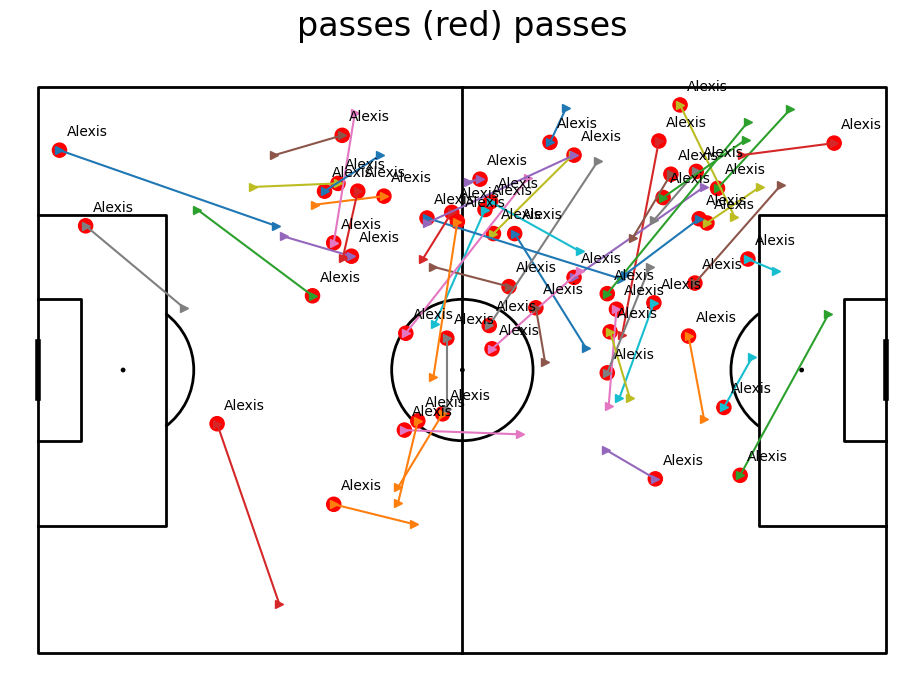

In [15]:
pitch = Pitch(line_color = "black")
fig, ax = pitch.draw(figsize=(10, 7))
#Size of the pitch in yards (!!!)
pitchLengthX = 120
pitchWidthY = 80
prev=0
count=0
posx=[]
posy=[]
#Plot the shots by looping through them.
for i,passes in passes.iterrows():
    #get the information 
    x=passes['x']
    y=passes['y']
    endx=passes['end_x']
    endy=passes['end_y']
    goal=passes['outcome_name']=='Pass'
    team_name=passes['team_name']
    player=passes['player_name']=='Alexis Mac Allister'
    #set circlesize
    circleSize=1
    #plot messi
    if (team_name==team2):
        if player:
            shotCircle=plt.Circle((x,y),circleSize,color="red")
            plt.text(x+1,y-2,passes['player_name'].split()[0])
            ax.add_patch(shotCircle)
            count=count+1
            posx.append(x)
            posy.append(y)
            posx.append(endx)
            posy.append(endy)
    
            
#            plt.plot()
            
            
            
#            plt.arrow(x,y,10,10,head_width=3,head_length=2)
'''
        else:
            shotCircle=plt.Circle((x,y),circleSize,color="red")     
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
 

    #plot England
    else:
        continue
        if goal:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue") 
            plt.text(pitchLengthX-x+1,pitchWidthY - y - 2 ,shot['player_name'])
 #           plt.arrow(x+1,y-2,5,1)
        else:
            shotCircle=plt.Circle((pitchLengthX-x,pitchWidthY - y),circleSize,color="blue")      
            shotCircle.set_alpha(.2)
 #           plt.arrow(x+1,y-2,5,1)
'''


#set title
for i in range(0, len(posx), 2):
    plt.plot(posx[i:i+2], posy[i:i+2], '->')
    
fig.suptitle("passes (red) passes", fontsize = 24)     
fig.set_size_inches(10, 7)
plt.show()

# USING THE CONTENT FROM MADABOUTSPORTS

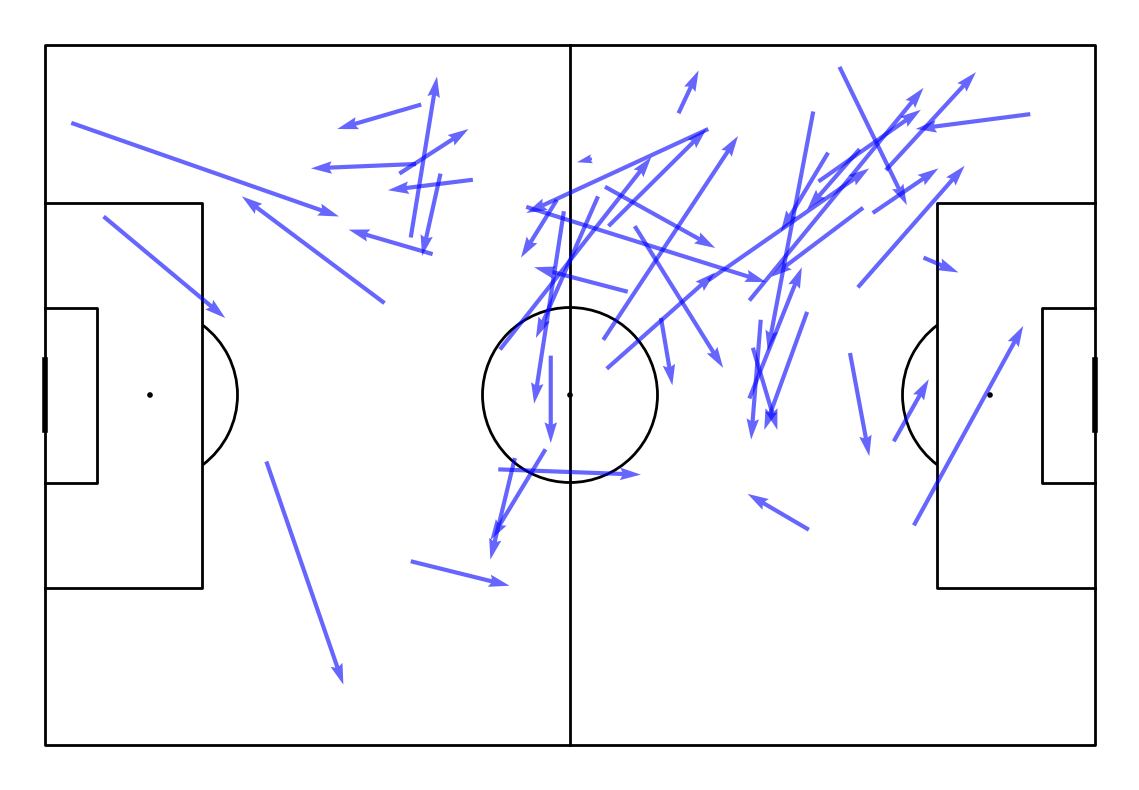

In [16]:
df1=df[df["type_name"]=="Pass"]

df2=df1[df1["team_name"]=="Argentina"]

df3=df2[df2["player_name"]=="Alexis Mac Allister"]

pitch=mplsoccer.Pitch(pitch_type='statsbomb',pitch_color='white',line_color='black')
fig,ax=pitch.draw(figsize=(14,8))
pitch.arrows(df3['x'],df3['y'],df3['end_x'],df3['end_y'],alpha=0.6,width=3,ax=ax,color='blue')
plt.show()

# PASS NETWORKS BLACK BOX CODE

/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_69377/3770341215.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jersey_data.rename(columns={'player_id':'pass_recipient_id'},inplace=True)
/var/folders/z_/lxkyxgq53_54hftk7vv3kdg80000gn/T/ipykernel_69377/3770341215.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jersey_data.rename(columns={'jersey_number':'pass_recipient'},inplace=True)


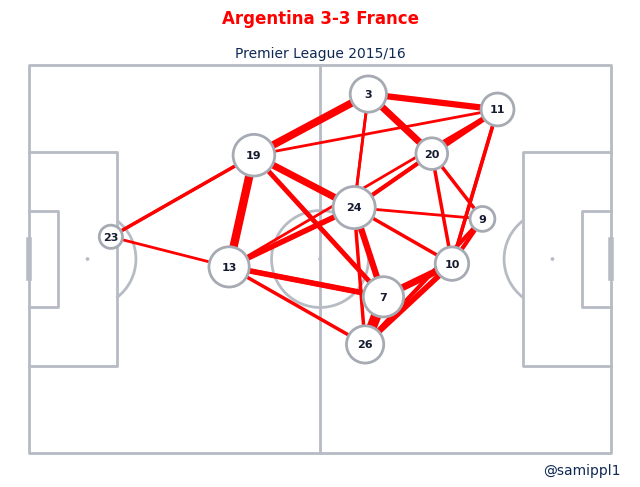

In [19]:
#LOADING DATA

parser= Sbopen()

df, related, freeze, tactics = parser.event(3869685)

#SELECTING TEAM

df = df[df['team_name']=='Argentina']

#SELECTING ACTION TYPE

passes = df[df['type_name']=='Pass']
filtered = passes[['player_name','x','y','end_x', 'end_y','pass_recipient_name','outcome_id','outcome_name','position_name']]

filtered[filtered['outcome_name'].isnull()]

df_lineup = parser.lineup(3869685)
jersey_data=df_lineup[['player_id','jersey_number']]

df= pd.merge(df,jersey_data,on='player_id')



#player id is the jersey number
df['passer'] = df['jersey_number']
passes = df[df['type_name']=='Pass']
successful = passes[passes['outcome_name'].isnull()]

rec= pd.to_numeric(successful['pass_recipient_id'],downcast='integer')
jersey_data.rename(columns={'player_id':'pass_recipient_id'},inplace=True)
jersey_data.rename(columns={'jersey_number':'pass_recipient'},inplace=True)
successful=pd.merge(df,jersey_data,on='pass_recipient_id')
successful

subs = df[df['type_name']=='Substitution']
subs = subs['minute']
firstSub=subs.min()


#FOR FRANCE SET firstSub into something else

#firstSub=63

successful = successful[successful['minute']<firstSub]

successful

successful.dtypes




successful

df['pass_recipient_id'].unique()

average_locations= successful.groupby('passer').agg({'x':['mean'],'y':['mean','count']})
average_locations.columns = ['x','y','count']

average_locations

pass_between = successful.groupby(['passer','pass_recipient']).id.count().reset_index()
pass_between.rename({'id':'pass_count'},axis='columns',inplace=True)
pass_between

pass_between= pass_between.merge(average_locations,left_on='passer',right_index=True)
pass_between


pass_between= pass_between.merge(average_locations,left_on='pass_recipient',right_index=True,suffixes=['','_end'])
pass_between

pass_between =pass_between[pass_between['pass_count']>3]
pass_between.drop_duplicates()
pass_between

average_locations['count'].values
pass_between['pass_count'].values

pass_between

# def create_arrow(row):
#     return mpatches.Arrow(1.2*row['x'], 0.8*row['y'], 1.2*row['x_end'], 0.8*row['y_end'], width=row['pass_count']*0.1, color='red')

pitch = Pitch(pitch_color='#FFFFFF', line_color='#B6BBC4')
# Set the figure size
fig, ax = pitch.draw(figsize=(8, 6), constrained_layout=True, tight_layout=False)

# Set the face color of the figure
fig.set_facecolor('#FFFFFF')

# Draw arrows and nodes
# arrows = pitch.arrows(1.2 * pass_between.x, 0.8 * pass_between.y, 1.2 * pass_between.x_end, 0.8 * pass_between.y_end, ax=ax,color='red', alpha=0.4,width=3)
pass_lines = pitch.lines(1.2*pass_between.x, 0.8*pass_between.y, 1.2*pass_between.x_end, 0.8*pass_between.y_end, lw=pass_between.pass_count*0.5,color='red', zorder=1, ax=ax)
                 
nodes = pitch.scatter(1.2 * average_locations.x, 0.8 * average_locations.y, s=20*average_locations['count'].values, color='white', edgecolors='#a6aab3', linewidth=2, alpha=1, zorder=1, ax=ax)

                 
# Annotate average_locations
for index, row in average_locations.iterrows():
    pitch.annotate(index, xy=(1.2 * row.x, 0.8 * row.y), c='#161A30',fontweight='bold', va='center', ha='center', size=8, ax=ax)

# Add the endnote
ax.text(114, 85, '@samippl1', color='#0E2954', va='bottom', ha='center', fontsize=10)

# Add the title
ax.set_title('Arsenal vs UTD', color='red', va='center', ha='center', fontsize=12,fontweight='bold',pad=20,loc='center')
ax.annotate('Premier League 2015/16', xy=(0.5, 1), xytext=(0, 0),
             xycoords='axes fraction', textcoords='offset points',
             fontsize=10, color='#0E2954', va='top', ha='center')


plt.show()

# MODIFIED ONE WITH PLAYER NAMES AND COLOUR CODES FOR POSTIONS

In [82]:
#ARGENTINA MATCH DIRECTORY 2022
#AUSTRALIA-3869151
#FRANCE-3869685
#MEXICO-3857289
#CROATIA-3869519
#SAUDI-3857300
#NETHERLANDS-3869321
#POLAND-3857264

In [83]:
#SELECTING THE MATCH
parser = Sbopen()
df, related, freeze, tactics = parser.event(3857289)
#get team names
team1, team2 = df.team_name.unique()
#A dataframe of shots
df = df[df['team_name']=='Argentina']

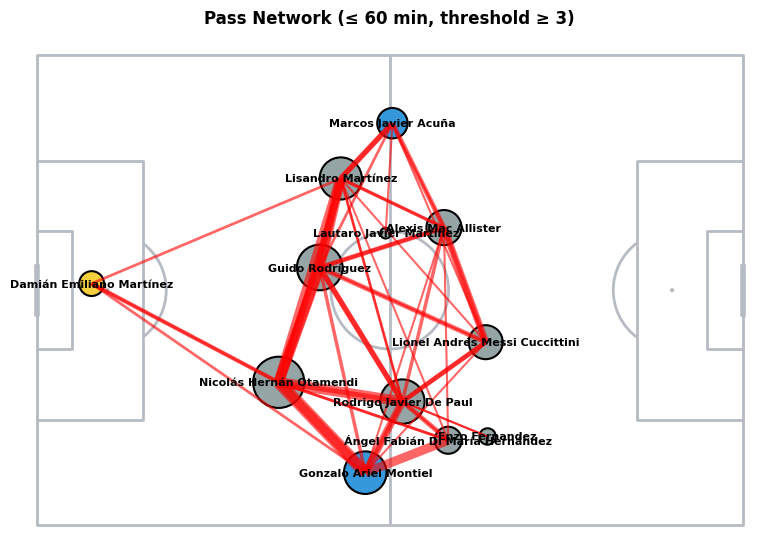

In [84]:
# =========================
# BUILD BASE PASS DATA
# =========================

base_passes = df[
    (df['type_name'] == 'Pass') &
    (df['outcome_name'].isnull()) &
    (df['player_name'].notna()) &
    (df['pass_recipient_name'].notna())
].copy()

# =========================
# PLOT FUNCTION
# =========================

def plot_pass_network(base_passes, threshold=1, max_minute=None):

    # Time filter
    if max_minute is not None:
        passes = base_passes[base_passes['minute'] <= max_minute]
    else:
        passes = base_passes.copy()

    # Average locations + position
    average_locations = passes.groupby('player_name').agg(
        x=('x', 'mean'),
        y=('y', 'mean'),
        count=('x', 'count'),
        position_name=('position_name', 'first')
    ).reset_index()

    # Position → color map
    position_colors = {
        'Goalkeeper': '#F4D03F',
        'Centre Back': '#3498DB',
        'Left Back': '#3498DB',
        'Right Back': '#3498DB',
        'Defensive Midfield': '#2ECC71',
        'Central Midfield': '#2ECC71',
        'Attacking Midfield': '#58D68D',
        'Left Wing': '#E74C3C',
        'Right Wing': '#E74C3C',
        'Centre Forward': '#C0392B'
    }

    average_locations['color'] = (
        average_locations['position_name']
        .map(position_colors)
        .fillna('#95A5A6')
    )

    # Pass counts
    pass_between = (
        passes
        .groupby(['player_name', 'pass_recipient_name'])
        .size()
        .reset_index(name='pass_count')
    )

    # Threshold filter
    pass_between = pass_between[pass_between['pass_count'] >= threshold]

    # Merge locations
    pass_between = pass_between.merge(
        average_locations.set_index('player_name'),
        left_on='player_name',
        right_index=True
    )

    pass_between = pass_between.merge(
        average_locations.set_index('player_name'),
        left_on='pass_recipient_name',
        right_index=True,
        suffixes=['', '_end']
    )

    # =========================
    # PLOT
    # =========================

    pitch = Pitch(pitch_color='#FFFFFF', line_color='#B6BBC4')
    fig, ax = pitch.draw(figsize=(8, 6))
    fig.set_facecolor('#FFFFFF')

    # Pass lines
    pitch.lines(
        pass_between.x,
        pass_between.y,
        pass_between.x_end,
        pass_between.y_end,
        lw=pass_between.pass_count * 0.5,
        color='red',
        alpha=0.6,
        ax=ax
    )

    # Player nodes
    pitch.scatter(
        average_locations.x,
        average_locations.y,
        s=20 * average_locations['count'],
        c=average_locations['color'],
        edgecolors='black',
        linewidth=1.5,
        ax=ax
    )

    # Labels
    for _, row in average_locations.iterrows():
        pitch.annotate(
            row['player_name'],
            (row.x, row.y),
            ha='center',
            va='center',
            fontsize=8,
            fontweight='bold',
            ax=ax
        )

    title = f'Pass Network (≤ {max_minute} min, threshold ≥ {threshold})' if max_minute else f'Pass Network (threshold ≥ {threshold})'
    ax.set_title(title, fontsize=12, fontweight='bold')

    plt.show()

# =========================
# USAGE
# =========================

plot_pass_network(base_passes, threshold=3, max_minute=60)



# TO SEE THE NETWORK QUANTITIES

In [85]:
pass_df = (
    df[
        (df['type_name'] == 'Pass') &
        (df['outcome_name'].isnull()) &
        (df['player_name'].notna()) &
        (df['pass_recipient_name'].notna())
    ]
    .groupby(['player_name', 'pass_recipient_name'])
    .size()
    .reset_index(name='pass_count')
    .sort_values('pass_count', ascending=False)
)

pass_df = pass_df.rename(columns={
    'player_name': 'passer',
    'pass_recipient_name': 'receiver'
})


In [86]:



# Example pass dataframe
# Replace this with your actual dataframe

# Create a directed graph
G = nx.DiGraph()

# Add edges with weights
for _, row in pass_df.iterrows():
    G.add_edge(
        row['passer'],
        row['receiver'],
        weight=row['pass_count']
    )

# Check nodes and edges
#print("Nodes:", G.nodes())
print("Edges with weights:", G.edges(data=True))


Edges with weights: [('Nicolás Hernán Otamendi', 'Gonzalo Ariel Montiel', {'weight': 18}), ('Nicolás Hernán Otamendi', 'Lisandro Martínez', {'weight': 16}), ('Nicolás Hernán Otamendi', 'Guido Rodríguez', {'weight': 15}), ('Nicolás Hernán Otamendi', 'Rodrigo Javier De Paul', {'weight': 9}), ('Nicolás Hernán Otamendi', 'Ángel Fabián Di María Hernández', {'weight': 4}), ('Nicolás Hernán Otamendi', 'Damián Emiliano Martínez', {'weight': 4}), ('Nicolás Hernán Otamendi', 'Cristian Gabriel Romero', {'weight': 2}), ('Nicolás Hernán Otamendi', 'Enzo Fernandez', {'weight': 2}), ('Nicolás Hernán Otamendi', 'Alexis Mac Allister', {'weight': 2}), ('Nicolás Hernán Otamendi', 'Nahuel Molina Lucero', {'weight': 2}), ('Nicolás Hernán Otamendi', 'Lionel Andrés Messi Cuccittini', {'weight': 2}), ('Gonzalo Ariel Montiel', 'Ángel Fabián Di María Hernández', {'weight': 14}), ('Gonzalo Ariel Montiel', 'Nicolás Hernán Otamendi', {'weight': 13}), ('Gonzalo Ariel Montiel', 'Rodrigo Javier De Paul', {'weight': 1

In [87]:
eig_centrality = nx.eigenvector_centrality(
    G,
    max_iter=1000,   # Increase iterations if it doesn't converge
    weight='weight'  # Use edge weight (e.g., number of passes)
)
bet_centrality=nx.betweenness_centrality(G)
clo_centrality=nx.closeness_centrality(G)
# Convert to a DataFrame for easy viewing

cent_df = pd.DataFrame()
cent_df['player name'] = eig_centrality.keys()  
cent_df['eigenvector_centrality'] = eig_centrality.values()
cent_df['betweenness_centrality']=bet_centrality.values()
cent_df['closeness_centrality']=clo_centrality.values()
cent_df = cent_df.sort_values('betweenness_centrality', ascending=False)


'''


'''
(cent_df)




,player name,eigenvector_centrality,betweenness_centrality,closeness_centrality
6,Lionel Andrés Messi Cuccittini,0.272788,0.115077,0.882353
0,Nicolás Hernán Otamendi,0.451639,0.101268,0.789474
10,Enzo Fernandez,0.104592,0.099172,0.750000
8,Marcos Javier Acuña,0.157343,0.058834,0.714286
2,Rodrigo Javier De Paul,0.382145,0.040130,0.833333
7,Alexis Mac Allister,0.253625,0.039928,0.681818
4,Guido Rodríguez,0.401862,0.036088,0.750000
9,Damián Emiliano Martínez,0.083107,0.028477,0.555556
3,Lisandro Martínez,0.361372,0.022481,0.714286
1,Gonzalo Ariel Montiel,0.334090,0.020202,0.714286


In [73]:
cent_df

,player name,eigenvector_centrality,betweenness_centrality
3,Enzo Fernandez,0.435212,0.089846
0,Nicolás Hernán Otamendi,0.416281,0.041188
4,Rodrigo Javier De Paul,0.371063,0.006840
1,Cristian Gabriel Romero,0.351632,0.006394
8,Lionel Andrés Messi Cuccittini,0.285072,0.099107
9,Alexis Mac Allister,0.261266,0.118904
5,Nahuel Molina Lucero,0.253338,0.009107
2,Leandro Daniel Paredes,0.233967,0.028549
6,Lisandro Martínez,0.170187,0.038767
7,Germán Alejandro Pezzella,0.161092,0.031567
